# Decode the Bioreactor — 07 Mechanistic model v2 (lag phase + byproduct metabolism)
Three optional terms were added to the mechanistic model (`src/bioreactor/model.py`, switched with `set_options`):

| option | term | biology | new parameter |
|---|---|---|---|
| `lag` | μ × (1 − e^(−t/t_lag)) | cells adapt after inoculation before growing at full speed | `t_lag` [d] |
| `byp_inhibition` | production × KPP/(KPP + P) | overflow metabolism slows as byproduct accumulates → plateau | `KPP` [g/L] |
| `byp_switch` | consumption × K_mu/(K_mu + μ) | cells switch to consuming byproduct when growth slows ("lactate shift") | `K_mu` [1/d] |

Variants compared here: **v1** (old model), **v2-lag** (lag only), **v2** (all three).
For each: the mechanistic model alone and `mech+ridge_day` (the hybrid), on the same folds.

**Note for the other notebooks**: the default is now v2. Their cached parameters (`outputs/params_cache/fold0.csv` …) were fitted with v1, are detected as not matching, and are refitted automatically on the next run. To keep using v1 there, add `from bioreactor.model import set_options; set_options(lag=False, byp_inhibition=False, byp_switch=False)` right after the imports.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bioreactor.data import load, to_arrays, STATES
from bioreactor import model as M
from bioreactor.model import NAMES, set_options, model_tag, predict_at_obs, simulate
from bioreactor.fit import fit_staged, initial_from_data
from bioreactor.hybrid import median_curve_preds, feature_table, ResidualCorrector, to_list
from bioreactor.evaluate import mape_row

df, tmpl, train_ids, test_ids = load(ROOT / "data")
splits = pd.read_csv(ROOT / "outputs" / "splits.csv")
dev_ids = splits.query("role == 'dev'").batch_id.tolist()
hold_ids = splits.query("role == 'holdout'").batch_id.tolist()
fold_of = splits.query("role == 'dev'").set_index("batch_id").fold.to_dict()

MAX_NFEV_STAGE, MAX_NFEV, N_STARTS = 20, 60, 1
FIT_KW = dict(residual="log", loss="soft_l1", f_scale=0.1)
CACHE = ROOT / "outputs" / "params_cache"; CACHE.mkdir(parents=True, exist_ok=True)
USE_CACHE = True

VARIANTS = {   # name -> options
    "v1":     dict(lag=False, byp_inhibition=False, byp_switch=False),
    "v2-lag": dict(lag=True,  byp_inhibition=False, byp_switch=False),
    "v2":     dict(lag=True,  byp_inhibition=True,  byp_switch=True),
}

In [2]:
def mech_params(ids, tag):
    """Parameters of the ACTIVE model variant fitted on `ids` (cache file includes the variant)."""
    f = CACHE / f"{tag}_{model_tag()}.csv"
    if USE_CACHE and f.exists():
        s = pd.read_csv(f, index_col=0).iloc[:, 0]
        if list(s.index) == NAMES:
            print(f"[{tag} {model_tag()}] from cache"); return s.values
    t0 = time.time()
    p, _ = fit_staged(to_arrays(df, ids), None, p_init=initial_from_data(df, ids),
                      max_nfev_stage=MAX_NFEV_STAGE, max_nfev_final=MAX_NFEV,
                      n_starts=N_STARTS, verbose=False, **FIT_KW)
    pd.Series(p, index=NAMES).to_csv(f); print(f"[{tag} {model_tag()}] fit {time.time()-t0:.0f} s")
    return p

def evaluate_variants(tr_ids, va_ids, tag, variants=VARIANTS):
    """For each model variant: fit on tr_ids; score mech alone and mech+ridge_day on va_ids."""
    a_tr, a_va = to_arrays(df, tr_ids), to_arrays(df, va_ids)
    rows = {"median": mape_row(a_va, median_curve_preds(df, tr_ids, a_va))}
    objs = {"a_va": a_va, "a_tr": a_tr}
    for vname, opts in variants.items():
        set_options(**opts)
        p = mech_params(tr_ids, tag)
        b_tr, b_va = predict_at_obs(p, a_tr), predict_at_obs(p, a_va)
        rows[f"mech_{vname}"] = mape_row(a_va, b_va)
        rows[f"mech_{vname}_train"] = mape_row(a_tr, b_tr)
        corr = ResidualCorrector("ridge_day").fit(feature_table(df, a_tr, b_tr))
        F_va = feature_table(df, a_va, b_va)
        rows[f"mech_{vname}+ridge_day"] = mape_row(a_va, to_list(F_va, corr.predict(F_va), a_va))
        objs[vname] = dict(p=pd.Series(p, index=list(NAMES)), b_va=b_va, opts=opts)
    set_options(**VARIANTS["v2"])     # leave the default active
    return pd.DataFrame(rows).T, objs

## 1. One fold: mechanistic model alone and as hybrid base
Rows `*_train` = error on the training batches (if v2 is much better there but not on validation → overfitting).

In [3]:
FOLD = 0
tr_ids = [b for b in dev_ids if fold_of[b] != FOLD]; va_ids = [b for b in dev_ids if fold_of[b] == FOLD]
t0 = time.time()
tab, objs = evaluate_variants(tr_ids, va_ids, tag=f"fold{FOLD}")
print(f"{time.time()-t0:.0f} s")
tab.round(2)

[fold0 v1] fit 69 s
[fold0 v2-lag] fit 69 s
[fold0 v2] fit 52 s
192 s


,vcd,tcd,substrate,byproduct,all
median,8.16,8.11,9.97,11.93,9.54
mech_v1,10.36,11.10,13.51,16.99,12.99
mech_v1_train,11.02,11.88,14.73,16.14,13.44
mech_v1+ridge_day,6.79,6.71,9.22,11.35,8.52
mech_v2-lag,10.07,10.69,13.73,17.69,13.04
mech_v2-lag_train,10.70,11.50,15.13,16.83,13.54
mech_v2-lag+ridge_day,6.79,6.70,9.00,11.35,8.46
mech_v2,7.60,8.04,17.06,15.79,12.12
mech_v2_train,8.63,9.08,18.20,15.38,12.82
mech_v2+ridge_day,6.78,6.73,8.76,11.02,8.32


### Did the systematic errors go away?
Mean **signed** % error by day (validation fold): v1 had VCD ≈ +20 % on day 1 and −10…−16 % on days 4–7, and a wrong byproduct plateau. Flat around 0 = the structure is right.

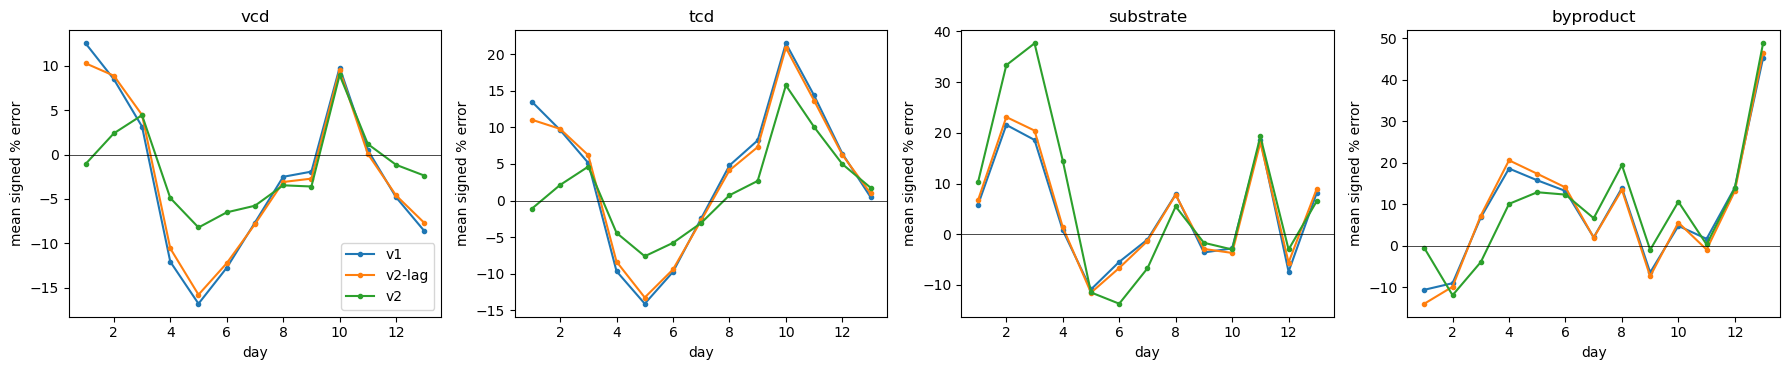

In [4]:
a_va = objs["a_va"]
Y = np.vstack(a_va.obs_y); day = np.round(np.concatenate(a_va.obs_t)).astype(int)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for v in VARIANTS:
    e = pd.DataFrame(100 * (np.vstack(objs[v]["b_va"]) - Y) / Y, columns=STATES).groupby(day).mean()
    for a, s in zip(ax, STATES):
        a.plot(e.index, e[s], "o-", ms=3, label=v)
for a, s in zip(ax, STATES):
    a.axhline(0, c="k", lw=0.5); a.set_title(s); a.set_xlabel("day"); a.set_ylabel("mean signed % error")
ax[0].legend(); plt.tight_layout(); plt.show()

### Fitted parameters (interpretation)
Check: no parameter sitting at its bound (`LB` / `UB`), and the new ones have sensible values, e.g. `t_lag` ≈ 0.3–1 d, `K_mu` a fraction of `mu_max`.

In [5]:
P = pd.DataFrame({v: objs[v]["p"] for v in VARIANTS})
bounds = pd.DataFrame({n: M.PARAMS[n][1:] for n in M.PARAMS}, index=["LB", "UB"]).T
P = P.join(bounds)
def at_bound(row):
    vals = row[list(VARIANTS)].dropna()
    return ", ".join(v for v, x in vals.items() if x <= row.LB * 1.02 or x >= row.UB * 0.98)
P["at_bound"] = P.apply(at_bound, axis=1)
P.round(4)

,v1,v2-lag,v2,LB,UB,at_bound
KI,5.0054,3.9361,2.4015,0.1000,50.0,
KN,1.4921,0.9957,0.5171,0.0010,2.0,
KPP,NaN,NaN,0.1278,0.0500,50.0,
KPc,9.9317,9.9783,0.2999,0.0010,10.0,"v1, v2-lag"
K_mu,NaN,NaN,5.0000,0.0050,5.0,v2
KdN,0.0924,0.0939,0.0301,0.0010,5.0,
Ks,0.2008,0.0018,0.0037,0.0010,5.0,
Nb,4.4254,4.8088,3.5096,0.0010,100.0,
Sb,75.1017,73.2998,66.0511,0.0010,200.0,
Ss,160.3346,172.5297,201.7388,0.0010,2000.0,


### Example trajectories (validation batches), v1 vs v2

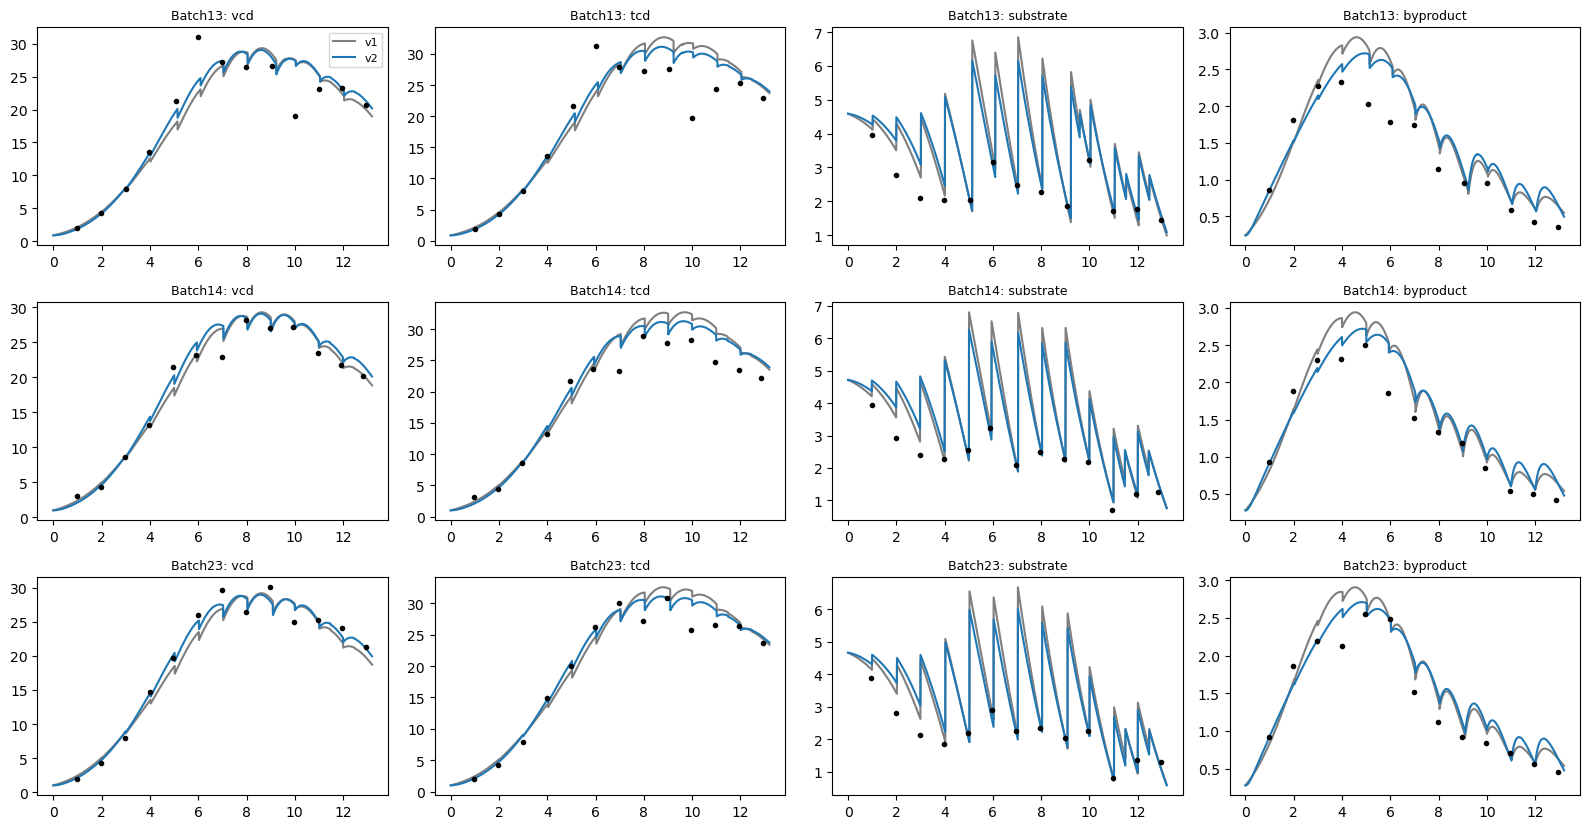

In [6]:
ids = a_va.ids[:3]
fig, ax = plt.subplots(len(ids), 4, figsize=(16, 2.8 * len(ids)))
for v, col in [("v1", "tab:gray"), ("v2", "tab:blue")]:
    set_options(**VARIANTS[v])
    traj = simulate(objs[v]["p"].values, a_va)
    for r, b in enumerate(ids):
        j = a_va.ids.index(b)
        for c, s in enumerate(STATES):
            ax[r, c].plot(a_va.t, traj[:, j, c], color=col, label=v)
            if v == "v2":
                ax[r, c].plot(a_va.obs_t[j], a_va.obs_y[j][:, c], "ko", ms=3)
            ax[r, c].set_title(f"{b}: {s}", fontsize=9)
set_options(**VARIANTS["v2"])
ax[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 2. 5-fold cross-validation
Fits 3 variants × 5 folds (cached per variant and fold, so only the first run is slow: ~1–2 min per fit).

In [7]:
RUN_CV = True
if RUN_CV:
    tabs = []
    for f in range(5):
        tr_ = [b for b in dev_ids if fold_of[b] != f]; va_ = [b for b in dev_ids if fold_of[b] == f]
        t_, _ = evaluate_variants(tr_, va_, tag=f"fold{f}")
        tabs.append(t_.assign(fold=f)); print(f"fold {f}:", t_["all"].round(2).to_dict())
    cv = pd.concat(tabs).rename_axis("variant").reset_index()
    cv = cv[~cv.variant.str.endswith("_train")]
    cv.to_csv(ROOT / "outputs" / "cv_scores_mech_v2.csv", index=False)
    display(cv.groupby("variant")[STATES + ["all"]].agg(["mean", "std"]).round(2).sort_values(("all", "mean")))

[fold0 v1] from cache
[fold0 v2-lag] from cache
[fold0 v2] from cache
fold 0: {'median': 9.54, 'mech_v1': 12.99, 'mech_v1_train': 13.44, 'mech_v1+ridge_day': 8.52, 'mech_v2-lag': 13.04, 'mech_v2-lag_train': 13.54, 'mech_v2-lag+ridge_day': 8.46, 'mech_v2': 12.12, 'mech_v2_train': 12.82, 'mech_v2+ridge_day': 8.32}
[fold1 v1] fit 84 s
[fold1 v2-lag] fit 68 s
[fold1 v2] fit 120 s
fold 1: {'median': 10.38, 'mech_v1': 13.14, 'mech_v1_train': 13.28, 'mech_v1+ridge_day': 9.1, 'mech_v2-lag': 13.33, 'mech_v2-lag_train': 13.37, 'mech_v2-lag+ridge_day': 9.06, 'mech_v2': 13.22, 'mech_v2_train': 13.12, 'mech_v2+ridge_day': 9.22}
[fold2 v1] fit 94 s
[fold2 v2-lag] fit 103 s
[fold2 v2] fit 92 s
fold 2: {'median': 10.07, 'mech_v1': 13.78, 'mech_v1_train': 13.18, 'mech_v1+ridge_day': 10.46, 'mech_v2-lag': 13.65, 'mech_v2-lag_train': 13.14, 'mech_v2-lag+ridge_day': 10.37, 'mech_v2': 12.96, 'mech_v2_train': 12.38, 'mech_v2+ridge_day': 9.91}
[fold3 v1] fit 88 s
[fold3 v2-lag] fit 59 s
[fold3 v2] fit 74 s
f

vcd          tcd       substrate       byproduct  \
                        mean   std   mean   std      mean   std      mean   
variant                                                                     
mech_v2+ridge_day       7.86  0.96   7.80  1.05     10.64  1.68     12.98   
mech_v2-lag+ridge_day   7.88  1.02   7.83  1.10     10.72  1.87     13.18   
mech_v1+ridge_day       7.92  1.03   7.86  1.10     10.92  1.83     13.10   
median                  8.58  0.55   8.65  0.59     11.69  1.40     13.04   
mech_v2                 8.66  0.70   9.06  0.73     18.52  1.86     15.63   
mech_v1                10.77  0.50  11.62  0.72     15.09  1.68     16.79   
mech_v2-lag            10.54  0.45  11.16  0.51     15.50  1.54     17.46   

                               all        
                        std   mean   std  
variant                                   
mech_v2+ridge_day      2.96   9.82  1.20  
mech_v2-lag+ridge_day  2.90   9.90  1.22  
mech_v1+ridge_day      2.69   9.95  1.17  
median                 2.79  10.49  0.92  
mech_v2                2.80  12.97  0.70  
mech_v1                2.66  13.57  0.52  
mech_v2-lag            2.69  13.66  0.55

## 3. Using v2 elsewhere
v2 is the default model now. Notebooks 03 / 04 / 06 pick it up automatically (their v1 caches are refitted on the next run). For the final submission with v2, run the final section of notebook 03 (`BASE = "mech"`, `METHOD = "ridge_day"`).